# Results notebook: Multilingual Retrieval Fairness (EN / HI / ML)

Reads the CSV files written by the scripts in `src/` and reproduces every table and figure in the report.
It does **not** re-run any model, so it finishes in seconds.

**How to run:** from the repo root, `jupyter notebook notebooks/results.ipynb`, then *Run all*.
Requires the files in `results/` (produced by the pipeline, see README run order).

In [1]:
import pathlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
R = pathlib.Path("results") if pathlib.Path("results").exists() else pathlib.Path("../results")
print("Reading from:", R.resolve())
LANGS = ["en", "hi", "ml"]
def need(name):
    f = R / name
    if not f.exists():
        raise FileNotFoundError(f"{name} missing: run the matching script first (see README).")
    return pd.read_csv(f)

Reading from: /home/svp/multilingual-retrieval-fairness/results


## 1. Baseline retrieval and the language gap
Exact cosine search over 488 passages, all 900 queries per language.

In [2]:
base = need("baseline.csv")
print(base.round(3).to_string(index=False))

 Recall@1  Recall@5  Recall@10  MRR@10    model lang  encode_seconds
    0.908     0.972      0.986   0.937 e5-small   en            15.5
    0.789     0.903      0.932   0.838 e5-small   hi            18.9
    0.769     0.899      0.934   0.829 e5-small   ml            21.4
    0.770     0.902      0.939   0.830   minilm   en            14.8
    0.536     0.762      0.821   0.633   minilm   hi            18.1
    0.026     0.053      0.077   0.039   minilm   ml            20.6
    0.913     0.983      0.989   0.944   bge-m3   en           168.1
    0.823     0.931      0.957   0.872   bge-m3   hi           214.2
    0.846     0.941      0.963   0.888   bge-m3   ml           235.5


In [3]:
gap = need("language_gap.csv")
fair = need("fairness_ratio.csv")
print("Gap to English (absolute and relative %):")
print(gap[["model","lang","Recall@1 gap","Recall@1 rel%","MRR@10 gap","MRR@10 rel%"]].to_string(index=False))
print("\nFairness ratio = worst-language Recall@1 / best-language Recall@1 (1.0 = perfectly fair):")
print(fair.round(3).to_string(index=False))

Gap to English (absolute and relative %):
   model lang  Recall@1 gap  Recall@1 rel%  MRR@10 gap  MRR@10 rel%
  bge-m3   hi         0.090            9.9       0.072          7.7
  bge-m3   ml         0.068            7.4       0.056          6.0
e5-small   hi         0.119           13.1       0.098         10.5
e5-small   ml         0.139           15.3       0.108         11.5
  minilm   hi         0.234           30.4       0.197         23.7
  minilm   ml         0.744           96.7       0.791         95.4

Fairness ratio = worst-language Recall@1 / best-language Recall@1 (1.0 = perfectly fair):
   model    en    hi    ml  fairness_ratio
  bge-m3 0.913 0.823 0.846           0.901
e5-small 0.908 0.789 0.769           0.847
  minilm 0.770 0.536 0.026           0.033


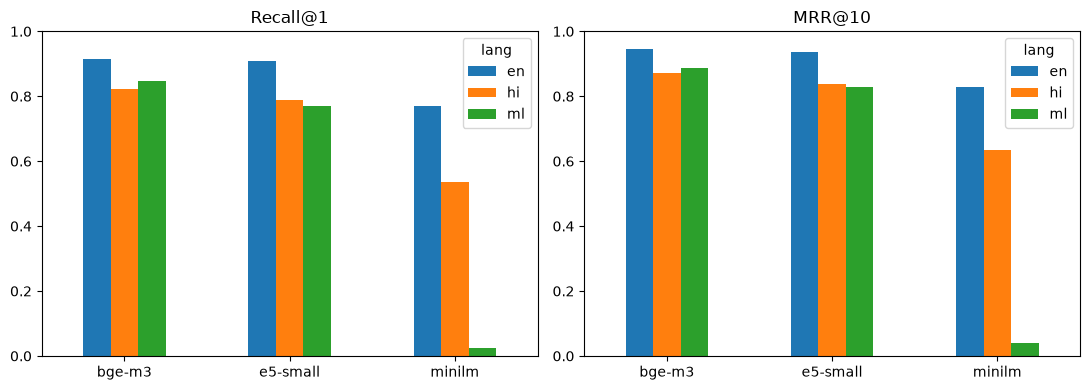

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ["Recall@1", "MRR@10"]):
    base.pivot(index="model", columns="lang", values=metric)[LANGS].plot.bar(ax=ax)
    ax.set_title(metric); ax.set_ylim(0, 1); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

## 2. Is the gap real? Bootstrap 95% intervals (Recall@1)
Intervals that do not overlap indicate a real difference.

   model lang  Recall@1  ci_lo  ci_hi
e5-small   en     0.908  0.888  0.926
e5-small   hi     0.789  0.761  0.814
e5-small   ml     0.769  0.741  0.794
  bge-m3   en     0.913  0.894  0.931
  bge-m3   hi     0.823  0.798  0.848
  bge-m3   ml     0.846  0.821  0.868


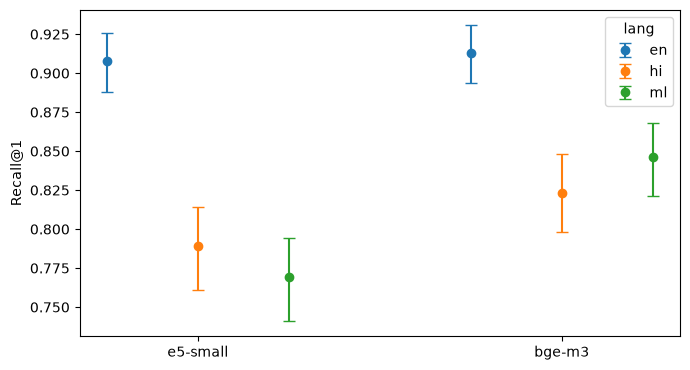

In [5]:
ci = need("bootstrap_ci.csv")
print(ci.to_string(index=False))
fig, ax = plt.subplots(figsize=(7, 3.8))
models = list(ci.model.unique()); w = 0.25
for j, lang in enumerate(LANGS):
    d = ci[ci.lang == lang].set_index("model").reindex(models)
    x = np.arange(len(models)) + (j - 1) * w
    ax.errorbar(x, d["Recall@1"], yerr=[d["Recall@1"] - d["ci_lo"], d["ci_hi"] - d["Recall@1"]], fmt="o", capsize=4, label=lang)
ax.set_xticks(range(len(models))); ax.set_xticklabels(models); ax.set_ylabel("Recall@1"); ax.legend(title="lang")
plt.tight_layout(); plt.show()

## 3. Mitigation A: hybrid search (dense + BM25)
Early runs used a regex tokenizer that split Indic words at combining marks; those results were discarded.
Below: whitespace tokens ("word") versus character 4-grams ("ngram4"). Weight = share given to the dense score.

In [6]:
hyb = need("hybrid.csv")
sel = hyb[hyb.method.isin(["dense", "bm25", "hybrid_w0.3", "hybrid_w0.5", "hybrid_w0.7"])]
t = sel.pivot_table(index=["dense_model", "tokenizer", "method"], columns="lang", values="Recall@1")[LANGS].round(3)
t

lang                                  en     hi     ml
dense_model tokenizer method                          
bge-m3      ngram4    bm25         0.843  0.691  0.788
                      hybrid_w0.3  0.900  0.758  0.850
                      hybrid_w0.5  0.932  0.808  0.893
                      hybrid_w0.7  0.946  0.849  0.906
            word      bm25         0.782  0.603  0.547
                      dense        0.913  0.823  0.846
                      hybrid_w0.3  0.870  0.721  0.642
                      hybrid_w0.5  0.917  0.794  0.696
                      hybrid_w0.7  0.938  0.840  0.797
e5-small    ngram4    bm25         0.843  0.691  0.788
                      hybrid_w0.3  0.892  0.746  0.836
                      hybrid_w0.5  0.923  0.792  0.866
                      hybrid_w0.7  0.940  0.829  0.880
            word      bm25         0.782  0.603  0.547
                      dense        0.908  0.789  0.769
                      hybrid_w0.3  0.860  0.699  0.622
                      hybrid_w0.5  0.902  0.762  0.674
                      hybrid_w0.7  0.928  0.808  0.747

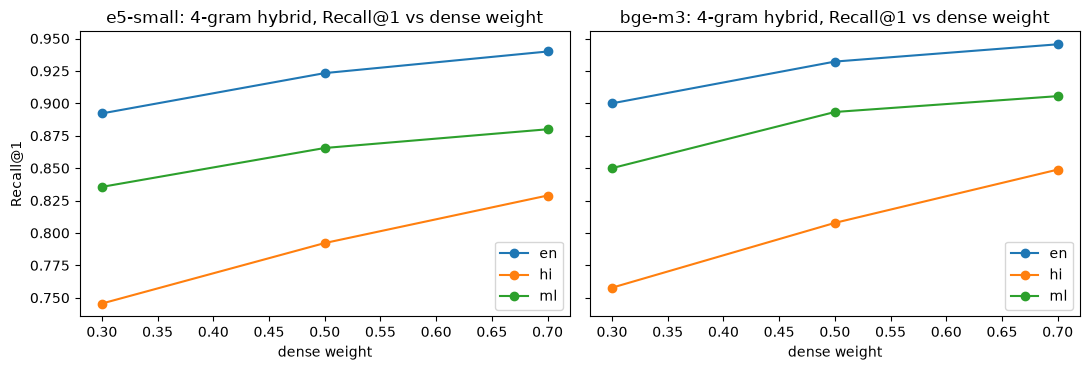

Note: weights were compared on the same queries that are reported, and the best weight sits at the edge of the grid.


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, dm in zip(axes, ["e5-small", "bge-m3"]):
    d = hyb[(hyb.dense_model == dm) & (hyb.tokenizer == "ngram4") & hyb.method.str.startswith("hybrid")]
    for lang in LANGS:
        s = d[d.lang == lang].sort_values("method")
        ax.plot([0.3, 0.5, 0.7], s["Recall@1"].values, marker="o", label=lang)
    ax.set_title(f"{dm}: 4-gram hybrid, Recall@1 vs dense weight"); ax.set_xlabel("dense weight"); ax.legend()
axes[0].set_ylabel("Recall@1"); plt.tight_layout(); plt.show()
print("Note: weights were compared on the same queries that are reported, and the best weight sits at the edge of the grid.")

## 4. Mitigation B: translation to English (retrieval)
NLLB-200 distilled 600M, greedy decoding.

In [8]:
tr = need("translation.csv")
tr[["model","lang","method","Recall@1","Recall@5","Recall@10","MRR@10"]].round(3).sort_values(["model","lang","method"]).reset_index(drop=True)

,model,lang,method,Recall@1,Recall@5,Recall@10,MRR@10
0,bge-m3,hi,translate+bm25,0.661,0.792,0.826,0.718
1,bge-m3,hi,translate+dense,0.847,0.947,0.967,0.889
2,bge-m3,hi,translate+hybrid_w0.5,0.829,0.922,0.950,0.871
3,bge-m3,hi,translate+hybrid_w0.7,0.862,0.950,0.972,0.901
4,bge-m3,ml,translate+bm25,0.632,0.780,0.820,0.696
5,bge-m3,ml,translate+dense,0.851,0.941,0.967,0.893
6,bge-m3,ml,translate+hybrid_w0.5,0.836,0.936,0.956,0.878
7,bge-m3,ml,translate+hybrid_w0.7,0.872,0.956,0.972,0.908
8,e5-small,hi,translate+bm25,0.661,0.792,0.826,0.718
9,e5-small,hi,translate+dense,0.797,0.931,0.956,0.853


## 5. Mitigation comparison (Recall@1)
Gap is measured against English dense retrieval for the same model.

method         baseline dense  hybrid w0.7 (4-gram BM25)  translate + dense  translate + hybrid w0.7
model    lang                                                                                       
bge-m3   hi             0.823                      0.849              0.847                    0.862
         ml             0.846                      0.906              0.851                    0.872
e5-small hi             0.789                      0.829              0.797                    0.838
         ml             0.769                      0.880              0.828                    0.843


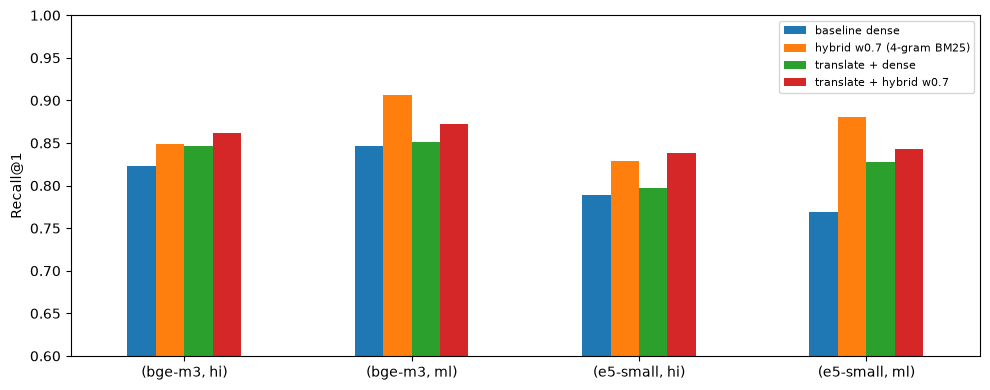

In [9]:
mc = need("mitigation_comparison.csv")
piv = mc.pivot_table(index=["model", "lang"], columns="method", values="Recall@1")
order = ["baseline dense", "hybrid w0.7 (4-gram BM25)", "translate + dense", "translate + hybrid w0.7"]
piv = piv[[c for c in order if c in piv.columns]]
print(piv.round(3).to_string())
ax = piv.plot.bar(figsize=(10, 4)); ax.set_ylim(0.6, 1.0); ax.set_ylabel("Recall@1")
ax.set_xlabel(""); plt.xticks(rotation=0); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

## 6. Answer quality (Qwen2.5 3b / 7b, n = 100 questions per language)
RAG accuracy uses the passage retrieved by bge-m3. Random guessing = 0.25.
The paired rows show translated minus native; an interval that excludes 0 supports a real gain.

In [10]:
ans = need("answer_ci.csv")
print(ans.to_string(index=False))

       llm lang                        pipeline  rag_acc  ci_lo  ci_hi
qwen2.5:3b   en                          native     0.82   0.74   0.89
qwen2.5:3b   hi                          native     0.59   0.49   0.69
qwen2.5:3b   hi                       translate     0.60   0.50   0.69
qwen2.5:3b   ml                          native     0.40   0.31   0.49
qwen2.5:3b   ml                       translate     0.56   0.46   0.65
qwen2.5:3b   hi translate minus native (paired)     0.01  -0.11   0.13
qwen2.5:3b   ml translate minus native (paired)     0.16   0.02   0.29
qwen2.5:7b   en                          native     0.86   0.79   0.92
qwen2.5:7b   hi                          native     0.59   0.50   0.68
qwen2.5:7b   hi                       translate     0.67   0.57   0.76
qwen2.5:7b   ml                          native     0.45   0.35   0.55
qwen2.5:7b   ml                       translate     0.59   0.49   0.68
qwen2.5:7b   hi translate minus native (paired)     0.08  -0.03   0.19
qwen2.

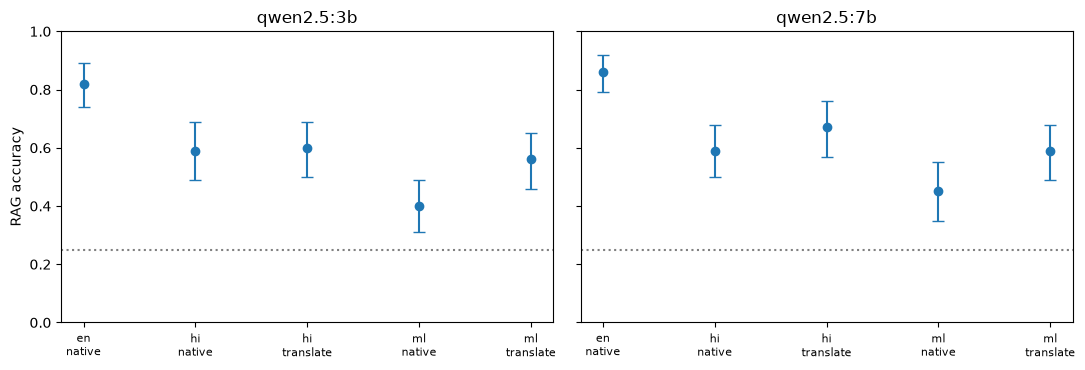

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, llm in zip(axes, sorted(ans.llm.unique())):
    d = ans[(ans.llm == llm) & ans.pipeline.isin(["native", "translate"])].copy()
    d["label"] = d.lang + "\n" + d.pipeline
    d = d.sort_values(["lang", "pipeline"], key=lambda s: s.map({"en":0,"hi":1,"ml":2,"native":0,"translate":1}).fillna(s))
    ax.errorbar(range(len(d)), d.rag_acc, yerr=[d.rag_acc - d.ci_lo, d.ci_hi - d.rag_acc], fmt="o", capsize=4)
    ax.set_xticks(range(len(d))); ax.set_xticklabels(d.label, fontsize=8); ax.axhline(0.25, ls=":", c="gray")
    ax.set_title(llm); ax.set_ylim(0, 1)
axes[0].set_ylabel("RAG accuracy"); plt.tight_layout(); plt.show()

In [12]:
paired = ans[ans.pipeline.str.contains("paired")].copy()
paired["supported"] = (paired.ci_lo > 0) | (paired.ci_hi < 0)
paired[["llm", "lang", "rag_acc", "ci_lo", "ci_hi", "supported"]].rename(columns={"rag_acc": "gain"})

,llm,lang,gain,ci_lo,ci_hi,supported
5,qwen2.5:3b,hi,0.01,-0.11,0.13,False
6,qwen2.5:3b,ml,0.16,0.02,0.29,True
12,qwen2.5:7b,hi,0.08,-0.03,0.19,False
13,qwen2.5:7b,ml,0.14,0.02,0.26,True


## 7. Mitigation C: fine-tuning e5-small (held-out passages)
Test passages were never seen in training. Base and fine-tuned are compared on the same held-out pool, so compare only within this table.

In [13]:
ft = need("finetune.csv")
ft.round(3).to_string(index=False)
ft.pivot_table(index="lang", columns="model", values="Recall@1").round(3)

model,e5-small base,e5-small finetuned
lang,,
en,0.926,0.926
hi,0.848,0.848
ml,0.881,0.862


## 8. Cost table
Single-machine CPU timings. The Malayalam corpus-translation time is an estimate because the original log was inflated by a laptop suspend.

In [14]:
need("cost_table.csv")

,step,CPU time,note
0,e5-small encode (3 langs),~55 s,"baseline, small model"
1,bge-m3 encode (3 langs),~620 s,about 10x e5-small
2,BM25 / hybrid,seconds,"no model, no GPU"
3,"Translate queries (900, per lang)","~1,400 s",about 1.5 s/query
4,Translate corpus hi (488),"3,277 s",about 6.8 s/passage
5,Translate corpus ml (488),"~3,500 s est.",log inflated by laptop suspend; pre-stall rate...
6,Fine-tune e5-small (1 epoch),663 s,no measurable gain
7,"LLM 3b/7b per question, native ml",10.6 s / 23.9 s,long Malayalam prompts
8,"LLM 3b/7b per question, translated ml",1.6 s / 3.6 s,plus translation cost


## 9. Take-aways (match the report)
- Every embedding model is worst on a non-English language; MiniLM collapses on Malayalam.
- Retrieval is not the main bottleneck for answers: the generator loses far more accuracy on Hindi and Malayalam than retrieval does.
- Hybrid search with 4-grams is the cheapest and strongest retrieval fix for Malayalam; Hindi remains unresolved.
- Translation helps Malayalam answer quality (paired intervals exclude 0, narrowly); the Hindi gain is not statistically supported.
- A light fine-tuning attempt gave no measurable gain.
- Limits: n = 100 for answer quality, weights tuned on reported queries, one LLM family, no distributed-scale experiments.